# Comparing Cross-Validation Techniques for Bank Marketing Prediction

**Author:** Rebeca Freitas

A Portuguese bank phones its clients to sell a term deposit. Fewer than 1 in 8 calls ends in a subscription, so the
bank wants a model that ranks clients by how likely they are to say yes. Before trusting such a model, we need an honest
estimate of how well it will perform on clients it has never seen. **Cross-validation (CV)** is the standard tool for
that, but there are many variants, and they do not all answer the same question.

This notebook compares CV techniques on the *Bank Marketing* data and asks four questions:

1. Do different CV techniques give different performance estimates for the same model?
2. Which estimate is closest to what the model actually delivers on **future** data?
3. How do the techniques differ in **bias**, **variance** and **computational cost**?
4. Do the conclusions hold on a second dataset (telecom customer churn)?

**Contents**

1. Setup
2. Data loading and validation
3. Exploratory look at the target
4. Features, models and a leakage check
5. The cross-validation techniques
6. Experiment 1: estimates from each technique (bank marketing)
7. Experiment 2: estimates versus the future
8. Experiment 3: bias and variance of the estimators
9. Experiment 4: leave-one-out on a small sample
10. Experiment 5: replication on telecom churn
11. Business view: what the model is worth to a campaign
12. Conclusions and limitations

## 1. Setup

In [1]:
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import (KFold, LeaveOneOut, RepeatedStratifiedKFold, StratifiedKFold,
                                     StratifiedShuffleSplit, TimeSeriesSplit, cross_val_predict,
                                     cross_validate, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=ConvergenceWarning)
pd.set_option("display.precision", 4)
pd.set_option("display.width", 140)

RANDOM_STATE = 42

# Chart style: one colour per model, used consistently in every figure.
SURFACE, INK, INK_2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
MODEL_COLORS = {"Logistic Regression": "#2a78d6", "Random Forest": "#eb6834", "Gradient Boosting": "#1baf7a"}
ACCENT = MODEL_COLORS["Logistic Regression"]

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "text.color": INK,
    "xtick.color": INK_2, "ytick.color": INK_2, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "font.family": "sans-serif", "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False, "figure.dpi": 110,
})


def find_file(name):
    """Look for a data file next to the notebook, in ./data, or in a Kaggle input folder."""
    for base in (Path("data"), Path("."), Path("/kaggle/input")):
        if base.exists():
            hits = sorted(base.rglob(name))
            if hits:
                return hits[0]
    raise FileNotFoundError(f"{name} not found. Put it in a 'data' folder next to this notebook.")

## 2. Data loading and validation

**Bank Marketing** (Moro, Laureano & Cortez, 2011) holds the results of phone campaigns run by a Portuguese bank between
May 2008 and November 2010. The target `y` says whether the client subscribed a term deposit. `bank-full.csv` has all
45,211 contacts, ordered by date; `bank.csv` is a random 10% sample (4,521 rows). Files are `;`-separated.

> Citation requested by the authors: S. Moro, R. Laureano and P. Cortez. *Using Data Mining for Bank Direct Marketing:
> An Application of the CRISP-DM Methodology.* Proceedings of the European Simulation and Modelling Conference
> (ESM'2011), pp. 117-121, Guimaraes, Portugal, October 2011. EUROSIS.

**Telco Customer Churn** (IBM sample data, published on Kaggle) describes 7,043 telecom customers and whether each one
left. It is not a banking dataset, but it is the same kind of problem (customer retention, binary outcome, mixed
categorical and numeric features), which makes it a useful second test of whether our conclusions travel.

Before any modelling, the files are checked against the dataset documentation.

In [2]:
BANK_COLUMNS = ["age", "job", "marital", "education", "default", "balance", "housing", "loan", "contact", "day",
                "month", "duration", "campaign", "pdays", "previous", "poutcome", "y"]
BANK_CATEGORIES = {
    "job": {"admin.", "unknown", "unemployed", "management", "housemaid", "entrepreneur", "student",
            "blue-collar", "self-employed", "retired", "technician", "services"},
    "marital": {"married", "divorced", "single"},
    "education": {"unknown", "secondary", "primary", "tertiary"},
    "default": {"yes", "no"}, "housing": {"yes", "no"}, "loan": {"yes", "no"}, "y": {"yes", "no"},
    "contact": {"unknown", "telephone", "cellular"},
    "month": {"jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"},
    "poutcome": {"unknown", "other", "failure", "success"},
}

bank_full = pd.read_csv(find_file("bank-full.csv"), sep=";")
bank_small = pd.read_csv(find_file("bank.csv"), sep=";")
telco_raw = pd.read_csv(find_file("WA_Fn-UseC_-Telco-Customer-Churn.csv"))


def validate_bank(df, expected_rows):
    return {
        "columns match the documentation": list(df.columns) == BANK_COLUMNS,
        f"{expected_rows:,} rows": len(df) == expected_rows,
        "no missing values": int(df.isna().sum().sum()) == 0,
        "no duplicated rows": not df.duplicated().any(),
        "categories within the documented values": all(set(df[c].unique()) <= ok for c, ok in BANK_CATEGORIES.items()),
        "pdays == -1 exactly when previous == 0": bool(((df["pdays"] == -1) == (df["previous"] == 0)).all()),
        "day between 1 and 31": bool(df["day"].between(1, 31).all()),
    }


merged = bank_small.merge(bank_full.drop_duplicates(), how="left", indicator=True)
total_charges = pd.to_numeric(telco_raw["TotalCharges"], errors="coerce")
blank_total = total_charges.isna()

report = pd.DataFrame({
    "bank-full.csv": validate_bank(bank_full, 45211),
    "bank.csv": {**validate_bank(bank_small, 4521), "every row also appears in bank-full.csv": bool((merged["_merge"] == "both").all())},
    "telco": {
        "7,043 rows x 21 columns": telco_raw.shape == (7043, 21),
        "customerID unique": bool(telco_raw["customerID"].is_unique),
        "no duplicated rows": not telco_raw.duplicated().any(),
        "TotalCharges blank only where tenure == 0": bool((telco_raw.loc[blank_total, "tenure"] == 0).all()),
    },
})
display(report.fillna("-"))
assert bool(report.stack().astype(bool).all()), "A validation check failed"

print(f"Telco: TotalCharges is stored as text because {int(blank_total.sum())} entries are blank "
      "(all new customers with tenure 0). They are set to 0 in the preparation step below.\n")

cat_cols = [c for c in BANK_CATEGORIES if c != "y"]
unknown = bank_full[cat_cols].eq("unknown").mean().mul(100).round(1)
print("The bank files have no empty cells, but 'unknown' is used as a category. Share of rows labelled 'unknown' (%):")
display(unknown[unknown > 0].to_frame("unknown (%)"))

,bank-full.csv,bank.csv,telco
columns match the documentation,True,True,-
"45,211 rows",True,-,-
no missing values,True,True,-
no duplicated rows,True,True,True
categories within the documented values,True,True,-
pdays == -1 exactly when previous == 0,True,True,-
day between 1 and 31,True,True,-
"4,521 rows",-,True,-
every row also appears in bank-full.csv,-,True,-
"7,043 rows x 21 columns",-,-,True


Telco: TotalCharges is stored as text because 11 entries are blank (all new customers with tenure 0). They are set to 0 in the preparation step below.

The bank files have no empty cells, but 'unknown' is used as a category. Share of rows labelled 'unknown' (%):


,unknown (%)
job,0.6
education,4.1
contact,28.8
poutcome,81.7


## 3. Exploratory look at the target

Two facts shape the whole study. First, the classes are **imbalanced**: only about 1 in 9 contacts subscribes, so plain
accuracy is misleading and we use threshold-free ranking metrics (ROC-AUC and average precision, which is the area under
the precision-recall curve). Second, `bank-full.csv` is **ordered by date**, and the file does not look the same from beginning
to end: the subscription rate is low for most of the file and jumps at the very end. A model trained on the past will be
used on a different future, and that matters for how we validate it.

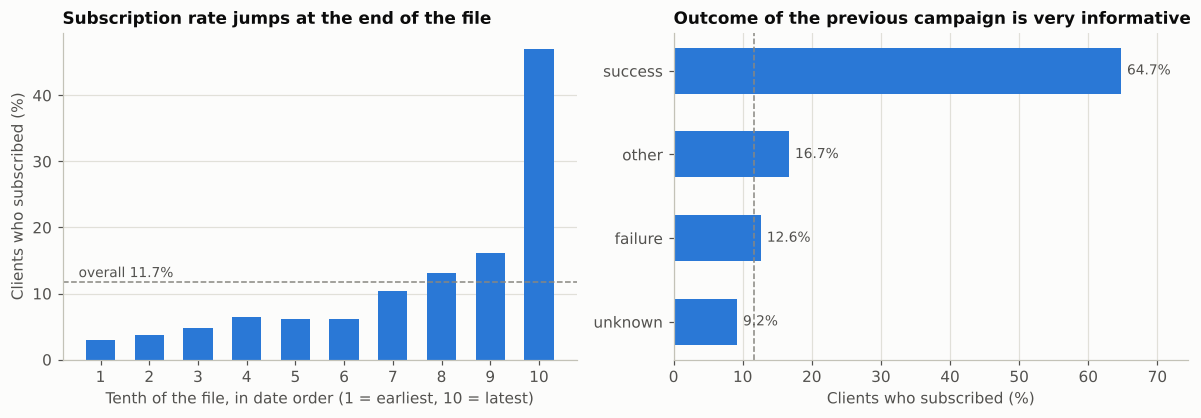

Bank Marketing: 11.7% positive.   Telco churn: 26.5% positive.


In [3]:
is_yes = bank_full["y"].eq("yes")
base_rate = is_yes.mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(11, 3.9))

# (a) subscription rate along the date-ordered file
tenth = pd.qcut(np.arange(len(bank_full)), 10, labels=False)
rate_by_tenth = is_yes.groupby(tenth).mean() * 100
ax = axes[0]
ax.bar(rate_by_tenth.index + 1, rate_by_tenth.values, color=ACCENT, width=0.6)
ax.axhline(base_rate, color=MUTED, lw=1, ls="--")
ax.text(0.55, base_rate + 0.8, f"overall {base_rate:.1f}%", ha="left", color=INK_2, fontsize=9)
ax.set_xticks(range(1, 11))
ax.set_xlabel("Tenth of the file, in date order (1 = earliest, 10 = latest)")
ax.set_ylabel("Clients who subscribed (%)")
ax.set_title("Subscription rate jumps at the end of the file")
ax.grid(axis="x", visible=False)
ax.set_axisbelow(True)

# (b) subscription rate by outcome of the previous campaign
by_prev = (is_yes.groupby(bank_full["poutcome"]).mean() * 100).sort_values()
ax = axes[1]
bars = ax.barh(by_prev.index, by_prev.values, color=ACCENT, height=0.55)
ax.bar_label(bars, fmt="%.1f%%", padding=4, color=INK_2, fontsize=9)
ax.axvline(base_rate, color=MUTED, lw=1, ls="--")
ax.set_xlim(0, by_prev.max() * 1.15)
ax.set_xlabel("Clients who subscribed (%)")
ax.set_title("Outcome of the previous campaign is very informative")
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)

fig.tight_layout()
plt.show()

churn_rate = telco_raw["Churn"].eq("Yes").mean() * 100
print(f"Bank Marketing: {base_rate:.1f}% positive.   Telco churn: {churn_rate:.1f}% positive.")

**A change in the campaign inside the file.** The file has no year column, but the order of the months reconstructs the
calendar: the sequence runs from May to December, then January to December again, and so on. Counting contacts per
month block shows that from the second June onwards (around mid-2009) the volume collapses from thousands of
contacts a month to a few hundred, and the subscription rate rises from about 7% to about 45%. The next cell locates
that point from the data.

In [4]:
# Rebuild the calendar from the order of the months: one "block" is a run of consecutive rows in the same month.
month_run = (bank_full["month"] != bank_full["month"].shift()).cumsum()
blocks = bank_full.groupby(month_run).agg(month=("month", "first"), rows=("month", "size"),
                                          subscribed_pct=("y", lambda s: s.eq("yes").mean() * 100))
blocks["first_row"] = blocks["rows"].cumsum() - blocks["rows"]

# The change starts at the first block after which every block has fewer than 1,000 contacts.
small = (blocks["rows"] < 1000).to_numpy()
change_block = next(i for i in range(len(small)) if small[i:].all())
REGIME_START = int(blocks["first_row"].iloc[change_block])

before, after = bank_full.iloc[:REGIME_START], bank_full.iloc[REGIME_START:]
regime = pd.DataFrame({
    "rows": [len(before), len(after)],
    "contacts per month block (median)": [blocks["rows"].iloc[:change_block].median(), blocks["rows"].iloc[change_block:].median()],
    "subscription rate (%)": [before["y"].eq("yes").mean() * 100, after["y"].eq("yes").mean() * 100],
}, index=["before the change", "after the change"])
print(f"The change starts at row {REGIME_START:,} of {len(bank_full):,} (month block #{change_block + 1}).")
display(regime.round(1))
display(blocks.iloc[change_block - 3: change_block + 3].round(1))

The change starts at row 39,752 of 45,211 (month block #13).


,rows,contacts per month block (median),subscription rate (%)
before the change,39752,3158.0,7.1
after the change,5459,247.0,45.5


,month,rows,subscribed_pct,first_row
month,,,,
10,mar,258,48.4,31201
11,apr,2718,16.6,31459
12,may,5575,9.6,34177
13,jun,642,37.5,39752
14,jul,207,36.7,40394
15,aug,772,34.2,40601


## 4. Features, models and a leakage check

**Feature preparation** is limited to stateless transformations (no statistics learned from the data), so it can safely be
done once, before cross-validation: a "contacted before" flag derived from `pdays`, a signed log for the skewed `balance`,
log scaling for the count variables. Anything that *learns* from the data (scaling, one-hot encoding) lives inside a
scikit-learn `Pipeline`, so it is re-fitted on the training part of every fold. Fitting a scaler on the whole dataset
before splitting is one of the most common ways to produce over-optimistic CV scores.

**Models** (deliberately simple, not tuned: the subject here is the validation, not the model): logistic regression,
random forest and gradient boosting.

**Leakage check.** `duration`, the length of the last call, is known only after the call has ended, and a call that is
about to become a subscription is a long call. A model that uses it would be useless for deciding *whom to call*.
We drop it, and the next cell shows how much it would have inflated the score.

In [5]:
def prepare_bank(df, drop_duration=True):
    X = df.drop(columns=["y"]).copy()
    if drop_duration:
        X = X.drop(columns=["duration"])
    X["contacted_before"] = (X["pdays"] != -1).astype(int)
    X["pdays"] = X["pdays"].where(X["pdays"] != -1, 0)
    X["balance"] = np.sign(X["balance"]) * np.log1p(X["balance"].abs())
    X["campaign"] = np.log1p(X["campaign"])
    X["previous"] = np.log1p(X["previous"])
    return X, (df["y"] == "yes").astype(int)


def prepare_telco(df):
    X = df.drop(columns=["customerID", "Churn"]).copy()
    X["TotalCharges"] = pd.to_numeric(X["TotalCharges"], errors="coerce").fillna(0.0)
    return X, (df["Churn"] == "Yes").astype(int)


def build_pipeline(model, X):
    numeric = X.select_dtypes(include="number").columns.tolist()
    categorical = [c for c in X.columns if c not in numeric]
    prep = ColumnTransformer([
        ("num", StandardScaler(), numeric),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical),
    ])
    return Pipeline([("prep", prep), ("model", model)])


MODELS = {
    "Logistic Regression": lambda: LogisticRegression(max_iter=1000),
    "Random Forest": lambda: RandomForestClassifier(n_estimators=100, min_samples_leaf=10, n_jobs=-1,
                                                    random_state=RANDOM_STATE),
    "Gradient Boosting": lambda: HistGradientBoostingClassifier(max_iter=100, learning_rate=0.1, max_leaf_nodes=15,
                                                                early_stopping=False, random_state=RANDOM_STATE),
}

# Chronological split: the first 80% of the (date-ordered) file is the development set, the last 20% is the "future".
# This is how the model would really be used: trained on the past, applied to what comes next.
X_bank, y_bank = prepare_bank(bank_full)
split_at = int(len(X_bank) * 0.8)
X_dev, y_dev = X_bank.iloc[:split_at], y_bank.iloc[:split_at]
X_future, y_future = X_bank.iloc[split_at:], y_bank.iloc[split_at:]
print(f"Development set: {len(X_dev):,} rows, {y_dev.mean():.1%} positive.   "
      f"Future set: {len(X_future):,} rows, {y_future.mean():.1%} positive.")

# The change found in Section 3 falls inside the future set, so the future set mixes two situations.
boundary = REGIME_START - split_at
print(f"Inside the future set: the first {boundary:,} rows still follow the old pattern "
      f"({y_future.iloc[:boundary].mean():.1%} positive); the last {len(y_future) - boundary:,} rows follow the new one "
      f"({y_future.iloc[boundary:].mean():.1%} positive).")

# How much would `duration` inflate the score?
leak = {}
for drop in (True, False):
    X_tmp, y_tmp = prepare_bank(bank_full.iloc[:split_at], drop_duration=drop)
    res = cross_validate(build_pipeline(MODELS["Gradient Boosting"](), X_tmp), X_tmp, y_tmp,
                         cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE), scoring="roc_auc")
    leak["without duration (used)" if drop else "with duration (leaky)"] = res["test_score"].mean()
display(pd.Series(leak, name="ROC-AUC, gradient boosting, stratified 5-fold").to_frame())

Development set: 36,168 rows, 6.7% positive.   Future set: 9,043 rows, 31.6% positive.
Inside the future set: the first 3,584 rows still follow the old pattern (10.3% positive); the last 5,459 rows follow the new one (45.5% positive).


,"ROC-AUC, gradient boosting, stratified 5-fold"
without duration (used),0.7133
with duration (leaky),0.9539


## 5. The cross-validation techniques

All techniques are run through the same scikit-learn machinery (a "splitter" that yields train/test index pairs), so the
only thing that changes between rows of the results is *how the data is split*.

| Technique | How it splits | What it is good for | What to watch |
|---|---|---|---|
| **Hold-out (80/20)** | one random stratified split | fastest, simplest | one number, high variance, wastes 20% of the data |
| **K-Fold (k=5, k=10)** | k random folds, each used once as test set | standard default | folds can have different class ratios when positives are rare |
| **Stratified K-Fold (k=5, k=10)** | k folds that keep the class ratio | the sensible default for imbalanced targets | assumes rows are exchangeable (no time order) |
| **Repeated Stratified K-Fold (5x3)** | stratified 5-fold, repeated with 3 reshuffles | lowers the variance caused by one particular split | 3x the cost |
| **Monte Carlo (20 x 20%)** | 20 independent random stratified 80/20 splits | number of splits independent of the test size | test sets overlap, so estimates are correlated |
| **Blocked K-Fold (k=5)** | 5 contiguous blocks, no shuffling | respects time order when the file is date-sorted | each fold is a different period |
| **Time Series Split (5)** | expanding window: train on the past, test on the next block | mimics deployment; never trains on the future | early folds train on little data, so they are pessimistic |
| **Leave-One-Out** | n folds of one row | uses almost all the data for training | n model fits; AUC is only defined on pooled predictions |

The two time-aware techniques are only valid for the date-ordered bank file. Leave-one-out is far too expensive on 36,000
rows, so it gets its own small-sample experiment (Experiment 4).

In [6]:
def make_splitters(seed=RANDOM_STATE, temporal=False):
    splitters = {
        "Hold-out (80/20)": StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=seed),
        "K-Fold (k=5)": KFold(5, shuffle=True, random_state=seed),
        "K-Fold (k=10)": KFold(10, shuffle=True, random_state=seed),
        "Stratified K-Fold (k=5)": StratifiedKFold(5, shuffle=True, random_state=seed),
        "Stratified K-Fold (k=10)": StratifiedKFold(10, shuffle=True, random_state=seed),
        "Repeated Stratified K-Fold (5x3)": RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=seed),
        "Monte Carlo (20 x 20%)": StratifiedShuffleSplit(n_splits=20, test_size=0.2, random_state=seed),
    }
    if temporal:
        splitters["Blocked K-Fold (k=5)"] = KFold(5, shuffle=False)
        splitters["Time Series Split (5)"] = TimeSeriesSplit(n_splits=5)
    return splitters


SCORING = {"roc_auc": "roc_auc", "avg_precision": "average_precision"}


def sd(values):
    return float(np.std(values, ddof=1)) if len(values) > 1 else np.nan


def evaluate_splitters(make_model, X, y, splitters):
    """Run every splitter for one model. SD columns are the spread of the per-fold scores."""
    rows = {}
    for name, cv in splitters.items():
        t0 = time.perf_counter()
        res = cross_validate(build_pipeline(make_model(), X), X, y, cv=cv, scoring=SCORING, n_jobs=1)
        rows[name] = {
            "n_fits": len(res["fit_time"]),
            "roc_auc": res["test_roc_auc"].mean(), "roc_auc_sd": sd(res["test_roc_auc"]),
            "avg_precision": res["test_avg_precision"].mean(), "avg_precision_sd": sd(res["test_avg_precision"]),
            "seconds": time.perf_counter() - t0,
        }
    return pd.DataFrame.from_dict(rows, orient="index").rename_axis("technique")


def dot_plot(results, techniques, models, metrics, title):
    """Mean score per technique (dot) with +-1 SD across folds (whisker), one colour per model."""
    fig, axes = plt.subplots(1, len(metrics), figsize=(11, 0.55 * len(techniques) + 1.8), sharey=True)
    axes = np.atleast_1d(axes)
    offsets = np.linspace(-0.24, 0.24, len(models))
    pos = np.arange(len(techniques))
    for ax, (metric, label) in zip(axes, metrics):
        for off, model in zip(offsets, models):
            d = results.loc[model].reindex(techniques)
            ax.errorbar(d[metric], pos + off, xerr=d[metric + "_sd"], fmt="o", color=MODEL_COLORS[model],
                        elinewidth=1.4, capsize=0, markersize=7, markeredgecolor=SURFACE, markeredgewidth=1.5,
                        label=model, zorder=3)
        ax.set_yticks(pos)
        ax.set_ylim(len(techniques) - 0.5, -0.5)
        ax.grid(axis="y", visible=False)
        ax.set_axisbelow(True)
        ax.set_xlabel(label)
    axes[0].set_yticklabels(techniques)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=len(models), bbox_to_anchor=(0.5, 1.0))
    fig.suptitle(title, x=0.01, y=1.06, ha="left", fontsize=12, fontweight="bold")
    fig.tight_layout()
    plt.show()

## 6. Experiment 1: estimates from each technique (bank marketing)

Every technique is applied to the **development set** (the first 80% of the file) for each of the three models. The
whiskers show one standard deviation of the per-fold scores. That is the spread *between folds*; it is not a standard
error of the mean, because folds share training data and are not independent.

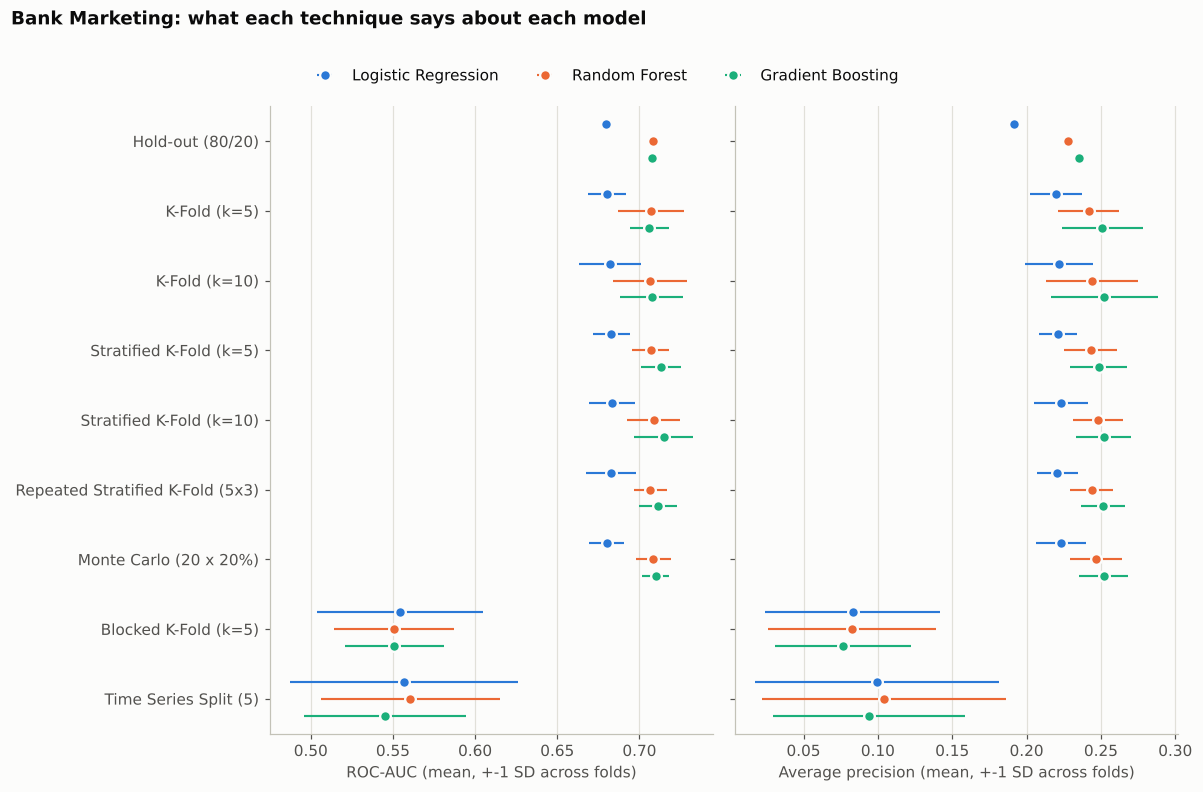

n_fits  roc_auc  roc_auc_sd  avg_precision  avg_precision_sd  seconds
model               technique                                                                                              
Logistic Regression Hold-out (80/20)                       1   0.6799         NaN         0.1913               NaN   0.5068
                    K-Fold (k=5)                           5   0.6804      0.0114         0.2197            0.0173   2.2800
                    K-Fold (k=10)                         10   0.6820      0.0189         0.2218            0.0227   4.6052
                    Stratified K-Fold (k=5)                5   0.6829      0.0113         0.2210            0.0127   2.3241
                    Stratified K-Fold (k=10)              10   0.6834      0.0141         0.2233            0.0180   4.5356
                    Repeated Stratified K-Fold (5x3)      15   0.6827      0.0150         0.2205            0.0137   6.6482
                    Monte Carlo (20 x 20%)                20   0.6802      0.0107         0.2232            0.0167   8.9918
                    Blocked K-Fold (k=5)                   5   0.5545      0.0505         0.0830            0.0588   1.9170
                    Time Series Split (5)                  5   0.5566      0.0693         0.0994            0.0820   1.1655
Random Forest       Hold-out (80/20)                       1   0.7085         NaN         0.2276               NaN   0.9759
                    K-Fold (k=5)                           5   0.7072      0.0200         0.2417            0.0205   4.6309
                    K-Fold (k=10)                         10   0.7065      0.0226         0.2442            0.0308  10.3996
                    Stratified K-Fold (k=5)                5   0.7069      0.0114         0.2432            0.0177   4.6888
                    Stratified K-Fold (k=10)              10   0.7087      0.0162         0.2480            0.0168  10.3596
                    Repeated Stratified K-Fold (5x3)      15   0.7066      0.0101         0.2438            0.0144  13.5985
                    Monte Carlo (20 x 20%)                20   0.7086      0.0105         0.2464            0.0174  18.9392
                    Blocked K-Fold (k=5)                   5   0.5505      0.0365         0.0826            0.0566   4.3009
                    Time Series Split (5)                  5   0.5606      0.0543         0.1041            0.0822   2.5837
Gradient Boosting   Hold-out (80/20)                       1   0.7074         NaN         0.2354               NaN   0.4716
                    K-Fold (k=5)                           5   0.7060      0.0119         0.2510            0.0271   2.3319
                    K-Fold (k=10)                         10   0.7076      0.0191         0.2523            0.0362   4.9998
                    Stratified K-Fold (k=5)                5   0.7133      0.0122         0.2486            0.0192   2.4710
                    Stratified K-Fold (k=10)              10   0.7148      0.0178         0.2518            0.0185   5.2585
                    Repeated Stratified K-Fold (5x3)      15   0.7113      0.0115         0.2514            0.0146   7.1220
                    Monte Carlo (20 x 20%)                20   0.7099      0.0083         0.2519            0.0166   9.7118
                    Blocked K-Fold (k=5)                   5   0.5508      0.0302         0.0767            0.0458   2.4026
                    Time Series Split (5)                  5   0.5452      0.0494         0.0941            0.0648   1.5896

In [7]:
bank_splitters = make_splitters(temporal=True)
cv_dev = pd.concat(
    {name: evaluate_splitters(make, X_dev, y_dev, bank_splitters) for name, make in MODELS.items()},
    names=["model"],
)
techniques_bank = list(bank_splitters)

dot_plot(cv_dev, techniques_bank, list(MODELS),
         [("roc_auc", "ROC-AUC (mean, +-1 SD across folds)"), ("avg_precision", "Average precision (mean, +-1 SD across folds)")],
         "Bank Marketing: what each technique says about each model")

display(cv_dev[["n_fits", "roc_auc", "roc_auc_sd", "avg_precision", "avg_precision_sd", "seconds"]].round(4))

**What we see.**

* **Random-split techniques agree.** For any given model, the seven techniques that shuffle rows give mean ROC-AUCs that are never more than 0.009 apart (logistic regression 0.680-0.683, random forest 0.707-0.709, gradient boosting 0.706-0.715). That is smaller than the fold-to-fold standard deviation (0.008-0.023), so these differences are not meaningful.
* **The model ranking is stable across them.** Random forest and gradient boosting beat logistic regression by roughly 0.025-0.03 AUC under every random-split technique, so all of them would lead to the same choice.
* **The two time-aware techniques disagree with all of the others.** Blocked K-Fold and Time Series Split put every model at 0.545-0.561 AUC, about 0.15 lower, with very wide whiskers (fold SD 0.03-0.07). Section 7 looks at why.
* **Average precision** follows the same pattern (0.19-0.25 for random splits, 0.08-0.10 for time-aware). It depends on how common the positive class is, which matters in Section 7.
* **Cost** is roughly proportional to the number of model fits: 1 for hold-out, 5 or 10 for K-Fold, 15 for the repeated version, 20 for Monte Carlo.

## 7. Experiment 2: estimates versus the future

A CV estimate is a *prediction* of how the model will do on new data. Here we can check that prediction. Each model is
trained on the whole development set and scored on the **future set** (the last 20% of the file, a period the CV
never saw). The dashed line is that realised score, the dots are what each CV technique had predicted.

Because the campaign changes inside the future set (Section 3), the score is also computed separately for the two
parts of the future set. The shaded band spans those two within-part scores. This matters: a pooled score can look better
than the score inside either part when the model gives higher scores, on average, to the part with more subscribers.

,future ROC-AUC (pooled),"ROC-AUC, old-pattern part","ROC-AUC, new-pattern part",future avg. precision (pooled)
Logistic Regression,0.6852,0.6499,0.6116,0.4892
Random Forest,0.6933,0.6246,0.5724,0.4637
Gradient Boosting,0.6931,0.6354,0.5949,0.4922


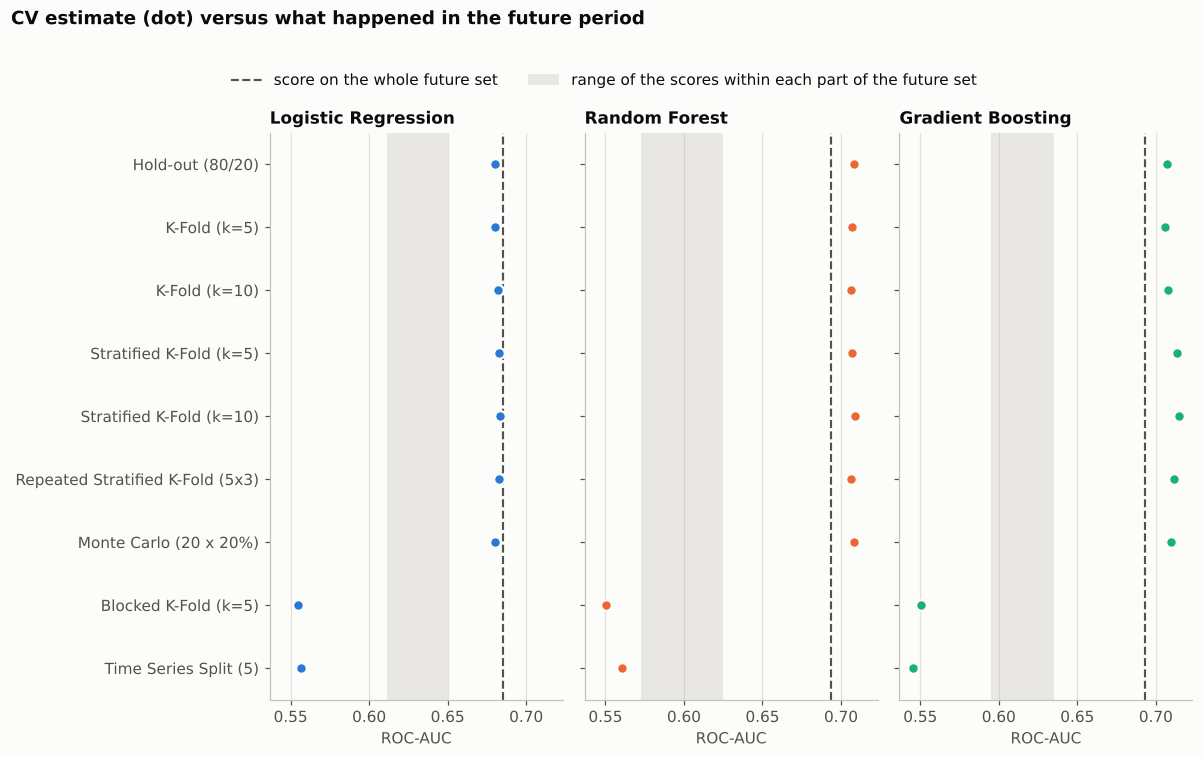

CV estimate minus pooled future ROC-AUC (positive = the CV was too optimistic):


model,Logistic Regression,Random Forest,Gradient Boosting
technique,,,
Hold-out (80/20),-0.0053,0.0152,0.0143
K-Fold (k=5),-0.0048,0.0139,0.0129
K-Fold (k=10),-0.0032,0.0131,0.0145
Stratified K-Fold (k=5),-0.0023,0.0136,0.0202
Stratified K-Fold (k=10),-0.0018,0.0154,0.0217
Repeated Stratified K-Fold (5x3),-0.0026,0.0133,0.0182
Monte Carlo (20 x 20%),-0.0050,0.0152,0.0169
Blocked K-Fold (k=5),-0.1308,-0.1428,-0.1423
Time Series Split (5),-0.1286,-0.1327,-0.1478


What the test block of each time-aware fold looks like:


train rows  test positive rate (%)  test rows whose month appears in training (%)
technique             fold                                                                                   
Blocked K-Fold (k=5)  1          28934                     3.0                                          100.0
                      2          28934                     4.9                                           38.0
                      3          28934                     6.6                                          100.0
                      4          28935                     5.4                                           32.7
                      5          28935                    13.7                                           58.9
Time Series Split (5) 1           6028                     4.2                                           32.0
                      2          12056                     6.1                                            6.4
                      3          18084                     6.0                                           12.3
                      4          24112                     5.8                                            0.1
                      5          30140                    15.0                                           50.6

In [8]:
future_scores, future_proba = {}, {}
for name, make in MODELS.items():
    fitted = build_pipeline(make(), X_dev).fit(X_dev, y_dev)
    proba = fitted.predict_proba(X_future)[:, 1]
    future_proba[name] = proba
    future_scores[name] = {
        "roc_auc": roc_auc_score(y_future, proba),
        "roc_auc_old_part": roc_auc_score(y_future.iloc[:boundary], proba[:boundary]),
        "roc_auc_new_part": roc_auc_score(y_future.iloc[boundary:], proba[boundary:]),
        "avg_precision": average_precision_score(y_future, proba),
    }
future_scores = pd.DataFrame(future_scores).T
display(future_scores.rename(columns={
    "roc_auc": "future ROC-AUC (pooled)", "roc_auc_old_part": "ROC-AUC, old-pattern part",
    "roc_auc_new_part": "ROC-AUC, new-pattern part", "avg_precision": "future avg. precision (pooled)"}))

fig, axes = plt.subplots(1, 3, figsize=(11, 0.5 * len(techniques_bank) + 1.9), sharey=True, sharex=True)
pos = np.arange(len(techniques_bank))
for ax, name in zip(axes, MODELS):
    est = cv_dev.loc[name].reindex(techniques_bank)["roc_auc"]
    lo, hi = sorted([future_scores.loc[name, "roc_auc_old_part"], future_scores.loc[name, "roc_auc_new_part"]])
    ax.axvspan(lo, hi, color=AXIS, alpha=0.35, lw=0, zorder=1)
    ax.axvline(future_scores.loc[name, "roc_auc"], color=INK_2, lw=1.4, ls="--", zorder=2)
    ax.plot(est, pos, "o", color=MODEL_COLORS[name], markersize=7, markeredgecolor=SURFACE, markeredgewidth=1.5, zorder=3)
    ax.set_title(name)
    ax.set_yticks(pos)
    ax.set_ylim(len(techniques_bank) - 0.5, -0.5)
    ax.grid(axis="y", visible=False)
    ax.set_axisbelow(True)
    ax.set_xlabel("ROC-AUC")
axes[0].set_yticklabels(techniques_bank)
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
fig.legend([Line2D([], [], color=INK_2, lw=1.4, ls="--"), Patch(color=AXIS, alpha=0.35, lw=0)],
           ["score on the whole future set", "range of the scores within each part of the future set"],
           loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.0))
fig.suptitle("CV estimate (dot) versus what happened in the future period",
             x=0.01, y=1.07, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
plt.show()

gap = (cv_dev["roc_auc"].unstack("model").reindex(techniques_bank) - future_scores["roc_auc"]).round(4)
print("CV estimate minus pooled future ROC-AUC (positive = the CV was too optimistic):")
display(gap)

# Why do the two time-aware techniques score so low? Look at what their test blocks contain.
rows = []
for label, cv in {"Blocked K-Fold (k=5)": KFold(5, shuffle=False), "Time Series Split (5)": TimeSeriesSplit(n_splits=5)}.items():
    for k, (tr, te) in enumerate(cv.split(X_dev), start=1):
        rows.append({"technique": label, "fold": k, "train rows": len(tr), "test positive rate (%)": y_dev.iloc[te].mean() * 100,
                     "test rows whose month appears in training (%)": X_dev.iloc[te]["month"].isin(set(X_dev.iloc[tr]["month"])).mean() * 100})
print("What the test block of each time-aware fold looks like:")
display(pd.DataFrame(rows).set_index(["technique", "fold"]).round(1))

**What we see.**

* **Random-split CV matches the pooled future score.** The pooled future ROC-AUC is 0.685 (logistic regression), 0.693 (random forest) and 0.693 (gradient boosting). Random-split estimates land within 0.002-0.022 of those values: slightly pessimistic for logistic regression, slightly optimistic for the two tree-based models. Time-aware CV is 0.13-0.15 below.
* **But the pooled future score is flattering.** Inside each part of the future set the AUC is lower: 0.65 and 0.61 for logistic regression, 0.62 and 0.57 for random forest, 0.64 and 0.59 for gradient boosting. A pooled AUC above both within-part values means part of the credit comes from ranking clients of one part against clients of the other, not from picking the right clients within a period. Judged by within-period skill, random-split CV was **optimistic** (0.68-0.71 predicted against 0.57-0.65 delivered) and time-aware CV was **pessimistic** (about 0.55). The truth sits between them.
* **Why are the time-aware estimates so low?** The file runs through the calendar, so every new block of rows contains months the model has not seen. In the blocked folds, only 38%, 33% and 59% of the test rows in folds 2, 4 and 5 fall in a month that appears in training; in the Time Series Split the share is 32%, 6%, 12%, 0.1% and 51%. Month is one of the model's features, and the subscription rate differs a lot between blocks (3% to 15%). These techniques therefore answer a harder question: *how does the model cope with a period unlike the one it was trained on?*
* **Average precision is not comparable across periods.** Future AP is 0.46-0.49 against 0.19-0.25 in CV, because 31.6% of the future clients subscribe against 6.7% in the development set. AP rises with the share of positives, so a higher AP here does not mean a better model.

## 8. Experiment 3: bias and variance of the estimators

Experiment 2 gives one verdict from one future window. To compare the estimators more carefully we need many repetitions,
and a setting without time drift, so we use `bank.csv`, the random 10% sample (4,521 clients).

Design: repeat 20 times. In each repeat, set aside a random stratified 30% as a test set. On the remaining 70%, compute the
CV estimate with every technique. Then fit the model on that whole 70% and score it on the 30%: this is the
"truth" the estimate was trying to predict. Because every technique sees the same data in each repeat, the comparison is
paired.

* **Bias** = average of (estimate - truth). Negative means pessimistic.
* **Spread** = how much the estimate itself moves from repeat to repeat.
* **RMSE** = typical size of the error, combining both.

The test sets here hold only about 1,350 clients, so the "truth" is itself noisy. That noise is the same for all
techniques within a repeat and does not affect their ranking.

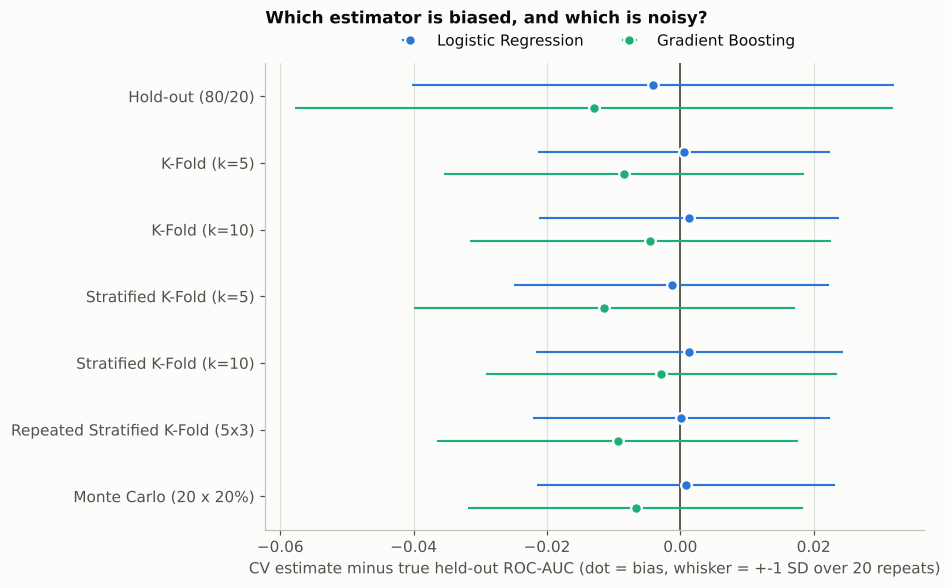

bias  spread  error_sd    rmse  seconds
model               technique                                                                  
Logistic Regression Hold-out (80/20)                 -0.0041  0.0292    0.0362  0.0355   0.0303
                    K-Fold (k=5)                      0.0006  0.0085    0.0219  0.0214   0.1411
                    K-Fold (k=10)                     0.0013  0.0083    0.0225  0.0220   0.2815
                    Stratified K-Fold (k=5)          -0.0013  0.0095    0.0237  0.0231   0.1418
                    Stratified K-Fold (k=10)          0.0013  0.0087    0.0230  0.0224   0.2849
                    Repeated Stratified K-Fold (5x3)  0.0001  0.0078    0.0223  0.0217   0.4129
                    Monte Carlo (20 x 20%)            0.0009  0.0096    0.0223  0.0218   0.5643
Gradient Boosting   Hold-out (80/20)                 -0.0129  0.0366    0.0448  0.0455   0.1583
                    K-Fold (k=5)                     -0.0084  0.0118    0.0270  0.0276   0.7869
                    K-Fold (k=10)                    -0.0045  0.0120    0.0271  0.0268   1.6030
                    Stratified K-Fold (k=5)          -0.0114  0.0136    0.0286  0.0301   0.7906
                    Stratified K-Fold (k=10)         -0.0028  0.0104    0.0263  0.0258   1.6130
                    Repeated Stratified K-Fold (5x3) -0.0094  0.0108    0.0271  0.0280   2.3826
                    Monte Carlo (20 x 20%)           -0.0067  0.0100    0.0252  0.0254   3.1595

In [9]:
N_REPEATS = 20
STUDY_MODELS = ["Logistic Regression", "Gradient Boosting"]
X_small, y_small = prepare_bank(bank_small)

records = []
for rep in range(N_REPEATS):
    seed = RANDOM_STATE + rep
    X_tr, X_te, y_tr, y_te = train_test_split(X_small, y_small, test_size=0.3, stratify=y_small, random_state=seed)
    for model_name in STUDY_MODELS:
        make = MODELS[model_name]
        truth = roc_auc_score(y_te, build_pipeline(make(), X_tr).fit(X_tr, y_tr).predict_proba(X_te)[:, 1])
        est = evaluate_splitters(make, X_tr, y_tr, make_splitters(seed))
        for tech, row in est.iterrows():
            records.append({"repeat": rep, "model": model_name, "technique": tech,
                            "estimate": row["roc_auc"], "truth": truth, "seconds": row["seconds"]})

study = pd.DataFrame(records)
study["error"] = study["estimate"] - study["truth"]
techniques_study = list(make_splitters())
summary = (study.groupby(["model", "technique"])
           .agg(bias=("error", "mean"), spread=("estimate", "std"), error_sd=("error", "std"),
                rmse=("error", lambda e: float(np.sqrt((e ** 2).mean()))), seconds=("seconds", "mean"))
           .reindex(pd.MultiIndex.from_product([STUDY_MODELS, techniques_study], names=["model", "technique"])))

fig, ax = plt.subplots(figsize=(8.6, 0.55 * len(techniques_study) + 1.6))
pos = np.arange(len(techniques_study))
offsets = np.linspace(-0.17, 0.17, len(STUDY_MODELS))
ax.axvline(0, color=INK_2, lw=1.2, zorder=2)
for off, model in zip(offsets, STUDY_MODELS):
    d = summary.loc[model]
    ax.errorbar(d["bias"], pos + off, xerr=d["error_sd"], fmt="o", color=MODEL_COLORS[model], elinewidth=1.4,
                capsize=0, markersize=7, markeredgecolor=SURFACE, markeredgewidth=1.5, label=model, zorder=3)
ax.set_yticks(pos)
ax.set_yticklabels(techniques_study)
ax.set_ylim(len(techniques_study) - 0.5, -0.5)
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)
ax.set_xlabel("CV estimate minus true held-out ROC-AUC (dot = bias, whisker = +-1 SD over 20 repeats)")
ax.set_title("Which estimator is biased, and which is noisy?", pad=26)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2)
fig.tight_layout()
plt.show()

display(summary.round(4))

**What we see.**

* **The single hold-out is the noisy one.** Its estimate moves about 3-4 times more from repeat to repeat (SD 0.029 for logistic regression and 0.037 for gradient boosting, against 0.008-0.014 for the other techniques) and its typical error is about 1.6 times larger (RMSE 0.036 and 0.046, against 0.021-0.023 and 0.025-0.030).
* **Bias is small for logistic regression** (within 0.0013 for every K-Fold style technique, -0.004 for hold-out) **and pessimistic for gradient boosting** (-0.003 to -0.013). The more flexible model gains more from extra training data, so a CV that trains on less data under-states what the final model will do. This fits what we see: 10-fold is less pessimistic than 5-fold (-0.0045 against -0.0084 for K-Fold, -0.0028 against -0.0114 for stratified).
* **Among the K-Fold style techniques the differences are small.** RMSE ranges only from 0.021 to 0.023 for logistic regression and from 0.025 to 0.030 for gradient boosting, which 20 repeats cannot separate. Stratification made no consistent difference with 11.5% positives. The repeated and Monte Carlo versions cost 3-4 times as much as 5-fold and did not give a measurable gain.
* **Part of the error cannot be removed by any technique.** The truth is itself measured on about 1,350 clients with roughly 150 subscribers, which is why the whiskers are wide (SD 0.022-0.029) even for the best techniques.

## 9. Experiment 4: leave-one-out on a small sample

Leave-one-out (LOO) trains on all rows except one, n times. It is nearly unbiased in size (each model sees n-1 rows), but
it is expensive, and with a single test row per fold, AUC can only be computed after **pooling** all n out-of-fold
predictions. To make the comparison fair, stratified 10-fold and 5-fold are also scored with pooled predictions.

We use logistic regression and 5 random samples of 800 clients from `bank.csv`. The truth is the AUC of the model trained on
the 800 clients and scored on the remaining 3,721.

In [10]:
LOO_N, LOO_DRAWS = 800, 5
rows = []
for draw in range(LOO_DRAWS):
    seed = RANDOM_STATE + draw
    X_s, X_rest, y_s, y_rest = train_test_split(X_small, y_small, train_size=LOO_N, stratify=y_small, random_state=seed)
    make = MODELS["Logistic Regression"]
    truth = roc_auc_score(y_rest, build_pipeline(make(), X_s).fit(X_s, y_s).predict_proba(X_rest)[:, 1])
    splitters = {
        "Leave-One-Out": LeaveOneOut(),
        "Stratified K-Fold (k=10)": StratifiedKFold(10, shuffle=True, random_state=seed),
        "Stratified K-Fold (k=5)": StratifiedKFold(5, shuffle=True, random_state=seed),
    }
    for name, cv in splitters.items():
        t0 = time.perf_counter()
        proba = cross_val_predict(build_pipeline(make(), X_s), X_s, y_s, cv=cv, method="predict_proba")[:, 1]
        rows.append({"draw": draw, "technique": name, "pooled_auc": roc_auc_score(y_s, proba), "truth": truth,
                     "n_fits": cv.get_n_splits(X_s), "seconds": time.perf_counter() - t0})

loo = pd.DataFrame(rows)
loo["error"] = loo["pooled_auc"] - loo["truth"]
loo_summary = loo.groupby("technique", sort=False).agg(
    pooled_auc=("pooled_auc", "mean"), truth=("truth", "mean"), bias=("error", "mean"),
    error_sd=("error", "std"), n_fits=("n_fits", "first"), seconds=("seconds", "mean"))
display(loo_summary.round(4))

,pooled_auc,truth,bias,error_sd,n_fits,seconds
technique,,,,,,
Leave-One-Out,0.6806,0.6959,-0.0153,0.0367,800,13.5592
Stratified K-Fold (k=10),0.6861,0.6959,-0.0097,0.0293,10,0.1657
Stratified K-Fold (k=5),0.6814,0.6959,-0.0144,0.0359,5,0.0831


**What we see.** Leave-one-out gave a pooled AUC of 0.681 against a truth of 0.696 (bias -0.015, error SD 0.037). Stratified 10-fold was closer (bias -0.010, error SD 0.029) and 5-fold was similar to leave-one-out (bias -0.014, error SD 0.036). With 5 samples these differences are not distinguishable, and that is the point: leave-one-out brought no visible accuracy gain, yet it fitted 800 models instead of 10 and took roughly 80 times longer (about 14 seconds against 0.17 seconds for each sample of 800 clients). On the 36,000-row development set it would be impractical.

## 10. Experiment 5: replication on telecom churn

Same three models, same techniques (without the two time-aware ones, since this dataset has no date), on all 7,043
Telco customers. If a conclusion from the bank data is a property of the techniques rather than of one dataset, it should
reappear here.

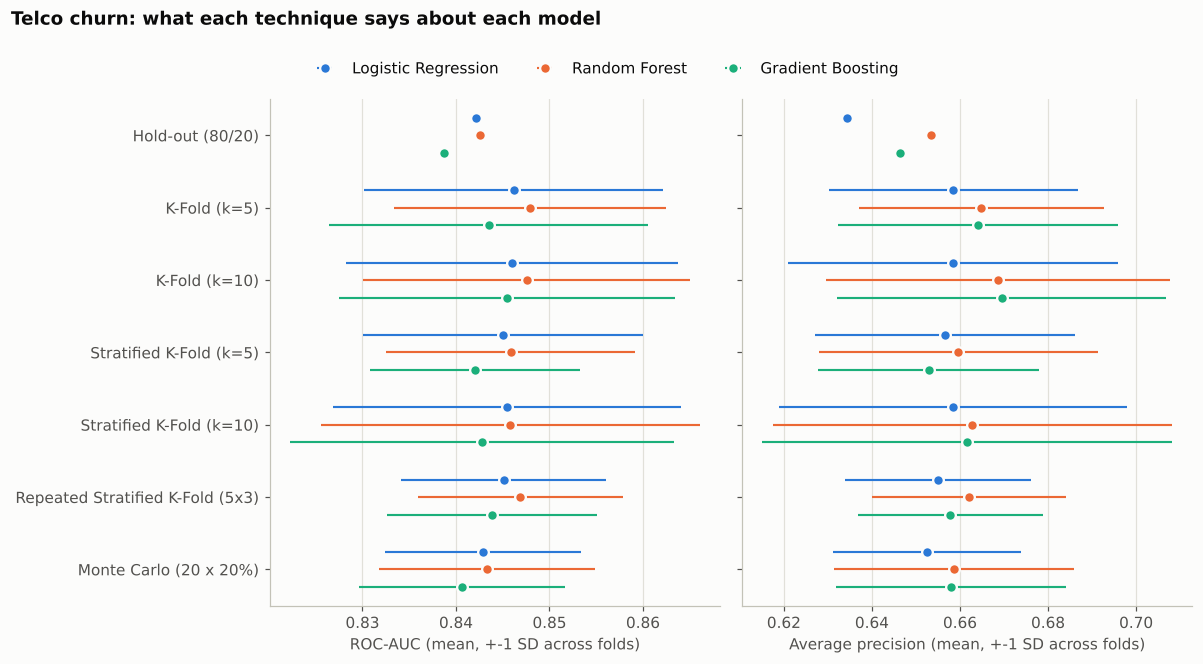

n_fits  roc_auc  roc_auc_sd  avg_precision  avg_precision_sd  seconds
model               technique                                                                                              
Logistic Regression Hold-out (80/20)                       1   0.8421         NaN         0.6343               NaN   0.0503
                    K-Fold (k=5)                           5   0.8462      0.0160         0.6585            0.0283   0.2057
                    K-Fold (k=10)                         10   0.8460      0.0177         0.6583            0.0375   0.4355
                    Stratified K-Fold (k=5)                5   0.8451      0.0150         0.6567            0.0296   0.2077
                    Stratified K-Fold (k=10)              10   0.8454      0.0186         0.6584            0.0396   0.4682
                    Repeated Stratified K-Fold (5x3)      15   0.8451      0.0110         0.6550            0.0210   0.6412
                    Monte Carlo (20 x 20%)                20   0.8429      0.0105         0.6525            0.0214   0.8528
Random Forest       Hold-out (80/20)                       1   0.8426         NaN         0.6534               NaN   0.2871
                    K-Fold (k=5)                           5   0.8479      0.0146         0.6648            0.0278   1.2780
                    K-Fold (k=10)                         10   0.8475      0.0175         0.6687            0.0391   2.7160
                    Stratified K-Fold (k=5)                5   0.8458      0.0133         0.6596            0.0317   1.2695
                    Stratified K-Fold (k=10)              10   0.8458      0.0203         0.6628            0.0453   2.6942
                    Repeated Stratified K-Fold (5x3)      15   0.8469      0.0110         0.6621            0.0220   4.1294
                    Monte Carlo (20 x 20%)                20   0.8433      0.0116         0.6586            0.0272   5.3528
Gradient Boosting   Hold-out (80/20)                       1   0.8387         NaN         0.6464               NaN   0.2105
                    K-Fold (k=5)                           5   0.8435      0.0171         0.6641            0.0318   0.9692
                    K-Fold (k=10)                         10   0.8454      0.0180         0.6694            0.0374   2.0218
                    Stratified K-Fold (k=5)                5   0.8420      0.0113         0.6529            0.0251   0.9476
                    Stratified K-Fold (k=10)              10   0.8428      0.0205         0.6616            0.0465   1.9475
                    Repeated Stratified K-Fold (5x3)      15   0.8438      0.0113         0.6578            0.0210   2.9345
                    Monte Carlo (20 x 20%)                20   0.8406      0.0110         0.6580            0.0261   3.8556

In [11]:
X_telco, y_telco = prepare_telco(telco_raw)
telco_splitters = make_splitters()
cv_telco = pd.concat(
    {name: evaluate_splitters(make, X_telco, y_telco, telco_splitters) for name, make in MODELS.items()},
    names=["model"],
)

dot_plot(cv_telco, list(telco_splitters), list(MODELS),
         [("roc_auc", "ROC-AUC (mean, +-1 SD across folds)"), ("avg_precision", "Average precision (mean, +-1 SD across folds)")],
         "Telco churn: what each technique says about each model")

display(cv_telco[["n_fits", "roc_auc", "roc_auc_sd", "avg_precision", "avg_precision_sd", "seconds"]].round(4))

**What we see.**

* **The same picture as the bank data.** Every technique puts every model between 0.839 and 0.848 AUC (logistic regression 0.842-0.846, random forest 0.843-0.848, gradient boosting 0.839-0.845). The single hold-out gives the lowest figure for all three models, but as one split it cannot tell us whether that is bias or luck.
* **The models are indistinguishable.** They differ by no more than about 0.005 AUC under any technique, while the fold-to-fold SD is 0.010-0.021. No validation scheme could crown a winner here, and the simplest model (logistic regression) is as good as the others.
* **Cost** follows the number of fits again, as in the bank data.

## 11. Business view: what the model is worth to a campaign

An AUC is hard to put in front of a marketing team. A **cumulative gains** view answers a more practical question: if the
bank can only call a fraction of its clients, how many of the eventual subscribers does it reach by calling the
highest-ranked ones first? The dashed diagonal is calling clients at random.

The model is chosen using development data only (the best average precision under stratified 10-fold CV), then scored
on the future period it never saw. Since the campaign changes inside that period, the gains are shown for the whole
future set and for each of its two parts. The two separate panels are the fairer picture of how well the model picks
*which clients* to call, because they do not reward the model for telling the two parts apart.

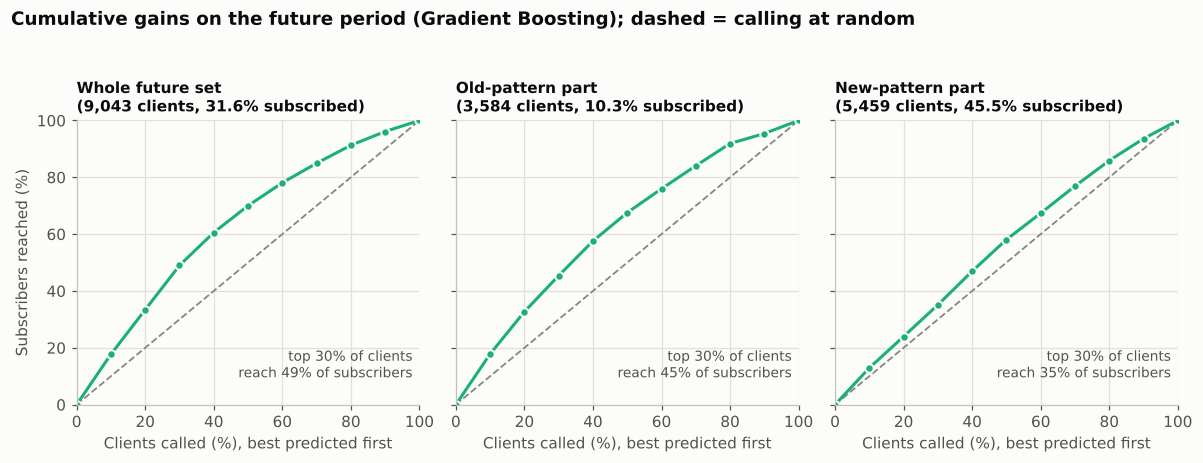

Model used: Gradient Boosting.
Mean predicted probability on the future set: 15.5%, actual subscription rate: 31.6%.


,subscription rate (%),top-decile rate (%),top-decile lift,subscribers reached by calling top 30% (%)
Whole future set,31.6,55.9,1.8,49.0
Old-pattern part,10.3,18.4,1.8,45.4
New-pattern part,45.5,58.8,1.3,35.1


,clients,subscribers,rate_%,lift,cum_share_of_subscribers_%
decile,,,,,
1,905,506,55.91,1.77,17.72
2,904,448,49.56,1.57,33.40
3,904,445,49.23,1.56,48.98
4,904,331,36.62,1.16,60.57
5,905,269,29.72,0.94,69.99
6,904,231,25.55,0.81,78.08
7,904,196,21.68,0.69,84.94
8,904,181,20.02,0.63,91.28
9,904,138,15.27,0.48,96.11


In [12]:
best_model = cv_dev.xs("Stratified K-Fold (k=10)", level="technique")["avg_precision"].idxmax()
p_future = future_proba[best_model]


def gains_table(y_true, proba):
    scored = pd.DataFrame({"y": np.asarray(y_true), "p": proba}).sort_values("p", ascending=False).reset_index(drop=True)
    scored["decile"] = pd.qcut(np.arange(len(scored)), 10, labels=False) + 1
    t = scored.groupby("decile").agg(clients=("y", "size"), subscribers=("y", "sum"))
    t["rate_%"] = t["subscribers"] / t["clients"] * 100
    t["lift"] = t["rate_%"] / (scored["y"].mean() * 100)
    t["cum_share_of_subscribers_%"] = t["subscribers"].cumsum() / t["subscribers"].sum() * 100
    return t


parts = {
    "Whole future set": (y_future, p_future),
    "Old-pattern part": (y_future.iloc[:boundary], p_future[:boundary]),
    "New-pattern part": (y_future.iloc[boundary:], p_future[boundary:]),
}
tables = {name: gains_table(*args) for name, args in parts.items()}

fig, axes = plt.subplots(1, 3, figsize=(11, 4.0), sharey=True)
for ax, (name, t) in zip(axes, tables.items()):
    x = np.r_[0, t.index * 10]
    y_cum = np.r_[0, t["cum_share_of_subscribers_%"].to_numpy()]
    ax.plot([0, 100], [0, 100], color=MUTED, lw=1.2, ls="--")
    ax.plot(x, y_cum, color=MODEL_COLORS[best_model], lw=2, marker="o", markersize=5.5,
            markeredgecolor=SURFACE, markeredgewidth=1.3)
    ax.text(98, 8, f"top 30% of clients\nreach {t.loc[3, 'cum_share_of_subscribers_%']:.0f}% of subscribers",
            ha="right", va="bottom", color=INK_2, fontsize=9)
    n_rows, rate = parts[name][0].shape[0], parts[name][0].mean() * 100
    ax.set_title(f"{name}\n({n_rows:,} clients, {rate:.1f}% subscribed)", fontsize=10)
    ax.set_xlabel("Clients called (%), best predicted first")
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 100)
axes[0].set_ylabel("Subscribers reached (%)")
fig.suptitle(f"Cumulative gains on the future period ({best_model}); dashed = calling at random",
             x=0.01, y=1.04, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
plt.show()

print(f"Model used: {best_model}.")
print(f"Mean predicted probability on the future set: {p_future.mean():.1%}, actual subscription rate: {y_future.mean():.1%}.")
summary_gain = pd.DataFrame({
    name: {"subscription rate (%)": parts[name][0].mean() * 100,
           "top-decile rate (%)": t.loc[1, "rate_%"], "top-decile lift": t.loc[1, "lift"],
           "subscribers reached by calling top 30% (%)": t.loc[3, "cum_share_of_subscribers_%"]}
    for name, t in tables.items()}).T
display(summary_gain.round(1))
display(tables["Whole future set"].round(2))

**What we see.**

* **The headline looks good.** On the whole future set, the top 10% of clients convert at 55.9% against 31.6% overall (lift 1.8x), and calling the top 30% reaches 49% of the subscribers.
* **The fairer view is weaker.** Within the old-pattern part the top decile has a lift of 1.8x and the top 30% reach 45% of subscribers, but within the new-pattern part the top decile has a lift of only 1.3x and the top 30% reach 35% (30% would be pure chance). Part of the headline gain comes from telling the two situations apart, which matches the pooled-versus-within AUC gap in Section 7.
* **The probability levels do not transfer.** The model's average predicted probability on the future set is 15.5%, while the true rate is 31.6%. Rankings carry over to a new period, at least partly. Probabilities do not, so they should not feed a budget forecast without being recalibrated on recent data.

## 12. Conclusions and limitations

### Answers to the four questions

1. **Do different CV techniques give different estimates?** Among techniques that shuffle rows, barely: for a given model the mean AUC moves by less than 0.01, less than the fold-to-fold variation (bank 0.680-0.715, telco 0.839-0.848). The exceptions are the time-aware techniques, which differ by about 0.15 AUC (0.55 against 0.70) on the date-ordered bank file.
2. **Which estimate is closest to the future?** Neither family matches it exactly. Random-split CV is close to the *pooled* future AUC, but that figure is flattered by the campaign change inside the future period; judged by within-period skill (0.57-0.65), random-split CV is optimistic. Time-aware CV (about 0.55) is pessimistic, because each of its test blocks brings months and rate levels the model has not seen. The honest message is a range, not a number.
3. **Bias, variance, cost?** The single hold-out has the same average as the others but 3-4 times the spread and about 1.6 times the typical error. 10-fold is slightly less pessimistic than 5-fold for gradient boosting. Repeating the CV or using Monte Carlo costs 3-4 times more for no measurable gain, and leave-one-out costs about 80 times more for none.
4. **Does it hold on a second dataset?** Yes. On telecom churn the random-split techniques agree within about 0.005 AUC and the model differences are smaller than the noise.

### What this means in practice

* For data whose rows can be treated as exchangeable, **stratified 10-fold CV** is a sound default. Repeat it only when the sample is small and a stable number is needed. Avoid a single hold-out for choosing between models.
* For data with a time order, **do not rely on one CV number**. Report a random-split estimate next to a chronological hold-out or time-aware CV, and look for drift (here, a change in the campaign) before trusting either.
* **Choosing the technique matters less than getting the setup right.** Leakage is the clearest example: including `duration` lifts the AUC from 0.71 to 0.95, a jump many times larger than any difference between techniques.
* Keep preprocessing inside the pipeline, report the spread together with the mean, and do not compare average precision across periods with different base rates.

### Limitations

* The models are not tuned. Tuning inside CV needs **nested** cross-validation, which is outside the scope of this notebook.
* The time analysis rests on **one** chronological cut (80/20) of one dataset with one change in regime. The calendar was inferred from the order of the months because the file has no year column, and the time-aware results depend on where the cut is made.
* The fold standard deviations are not standard errors, and Experiments 3 and 4 use 20 and 5 repetitions. Differences below about 0.005 AUC should not be read as real.
* In Experiment 3 the "truth" is a single noisy test split of about 1,350 clients.
* Telco churn has no dates and is not a banking problem, so it tests the comparison of techniques, not the banking findings.
* Only threshold-free ranking metrics are used. A real campaign would also need a decision threshold and a cost per call.

### References

* S. Moro, R. Laureano and P. Cortez (2011). *Using Data Mining for Bank Direct Marketing: An Application of the CRISP-DM Methodology.* ESM'2011, pp. 117-121. EUROSIS.
* *Telco Customer Churn*, IBM sample data, published on Kaggle.
* Pedregosa et al. (2011). *Scikit-learn: Machine Learning in Python.* Journal of Machine Learning Research 12, 2825-2830.

In [13]:
print(f"Python packages: pandas {pd.__version__}, numpy {np.__version__}, scikit-learn {sklearn.__version__}")
print(f"Random seed: {RANDOM_STATE}")

Python packages: pandas 3.0.5, numpy 2.5.3, scikit-learn 1.9.1
Random seed: 42
